# 1 Creating Object

In [1]:
from main import *

# 2 Eigenvalue, Stiffness Analysis

case              rho        T        V     Y1     Y2     Y3        |l1|        |l2|        |l3|        |l4|        |l5|        |l6|         R_s    dx_max(m)
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
inlet           4.483   1000.0    15.78  0.799  0.101  0.100   2.050e+04   1.272e+03   1.191e+03   2.311e-03   4.739e-13   0.000e+00   8.870e+06    9.758e-05
jump            2.281   2177.3    31.74  0.603  0.076  0.321   1.137e+07   1.851e+06   1.523e+06   4.601e+01   2.008e-09   0.000e+00   2.472e+05    1.758e-07
outlet          1.512   5810.3    56.50  0.000  0.000  1.000   4.372e+05   1.410e+00   1.408e+00   4.773e-04   5.116e-10   0.000e+00   3.106e+05    4.575e-06

jump index = 63, x = 54.81 um, T = 2177 K


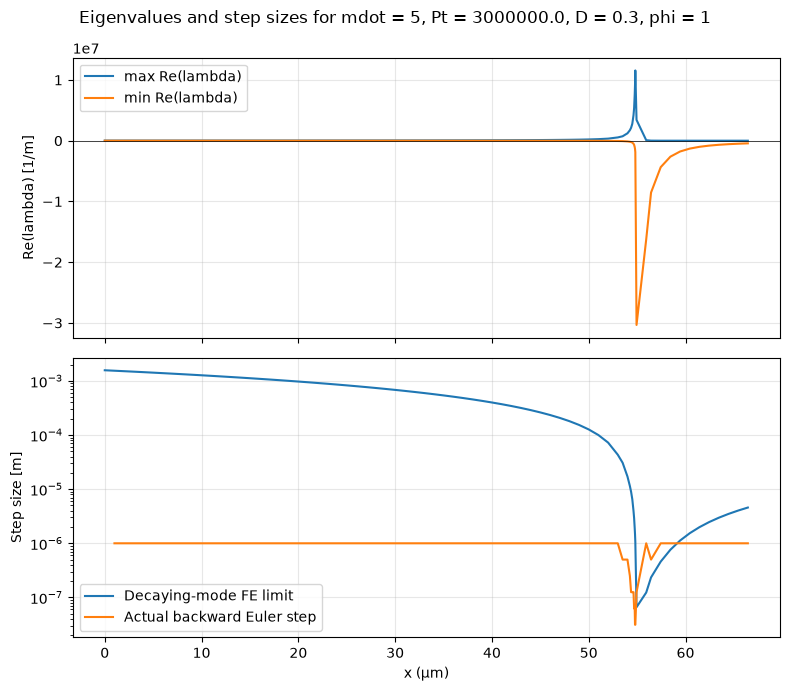

In [6]:
mdot = 5
Pt = 3e6
D = 0.3
phi = 1

Ar = 1.8e13 / np.sqrt(1000.0)
Ea = 17614.0 * 8.314e3
test = chamber_solver(mdot, Pt, D, phi, Ar, Ea)

J0, eigenvalues = test.stiffness()

x, states = test.solve(dx=1e-6, Y_tol=1e-6)
E, Rs, dx = test.stability_along_solution(x, states, mdot, Pt, D, phi)

state0, R, gamma, h1, h2, h3 = test.initial_conditions()
dY = np.max(np.abs(np.diff(states[:, 3:], axis=0)), axis=1)
jump = np.argmax(dY)

case_names = ["inlet", "jump", "outlet"]
case_states = [states[0], states[jump], states[-1]]

print(f"{'case':<12}{'rho':>9}{'T':>9}{'V':>9}{'Y1':>7}{'Y2':>7}{'Y3':>7}"
      f"{'|l1|':>12}{'|l2|':>12}{'|l3|':>12}{'|l4|':>12}{'|l5|':>12}{'|l6|':>12}"
      f"{'R_s':>12}{'dx_max(m)':>13}")
print("-" * 180)

for name, u in zip(case_names, case_states):
    J = test.jacobian(u, R, gamma, h1, h2, h3)
    ev = np.sort(np.abs(la.eigvals(J)))[::-1]
    nz = ev[ev > 1e-8 * ev[0]]
    Rs_i = nz[0] / nz[-1] if nz.size > 1 else np.nan
    dx_i = 2.0 / nz[0]
    Ep = np.pad(ev, (0, max(0, 6 - len(ev))), constant_values=np.nan)
    print(f"{name:<12}{u[0]:9.3f}{u[1]:9.1f}{u[2]:9.2f}{u[3]:7.3f}{u[4]:7.3f}{u[5]:7.3f}"
          + "".join(f"{e:12.3e}" for e in Ep[:6])
          + f"{Rs_i:12.3e}{dx_i:13.3e}")

print(f"\njump index = {jump}, x = {x[jump]*1e6:.4g} um, T = {states[jump,1]:.4g} K")

# 3 Backward Euler's Implementation

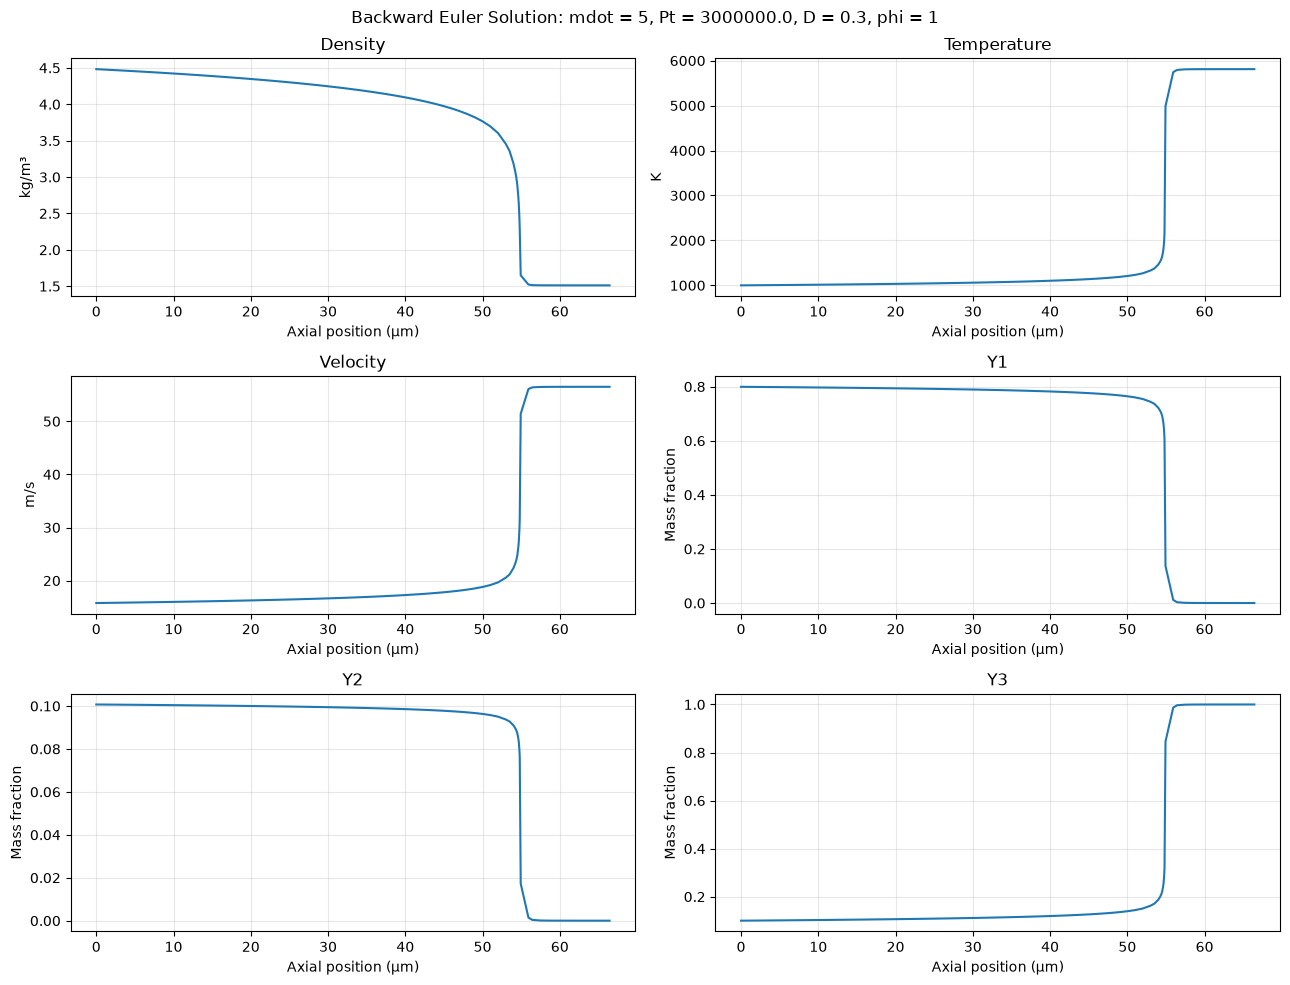

In [4]:
def plot_solution(x, states):
    labels = [
        ("Density", "kg/m³"),
        ("Temperature", "K"),
        ("Velocity", "m/s"),
        ("Y1", "Mass fraction"),
        ("Y2", "Mass fraction"),
        ("Y3", "Mass fraction")
    ]

    fig, axes = plt.subplots(3, 2, figsize=(13, 10))
    axes = axes.flatten()

    for i, (name, units) in enumerate(labels):
        axes[i].plot(x * 1e6, states[:, i])
        axes[i].set_title(name)
        axes[i].set_xlabel("Axial position (µm)")
        axes[i].set_ylabel(units)
        axes[i].grid(alpha=0.3)

    fig.suptitle(f"Backward Euler Solution: mdot = {mdot}, Pt = {Pt}, D = {D}, phi = {phi}")
    fig.tight_layout()
    plt.show()

x, states = test.solve(dx=1e-6, Y_tol=1e-6)

plot_solution(x, states)

# 4 Visualizing the Flow

(mdot=0.02 kg/s, Pt=1e+06 Pa, D=0.01 m, phi=1)
  state0 = [1.4943e+00 1.0000e+03 1.7042e+02 7.9928e-01 1.0072e-01 1.0000e-01],  M0 = 0.180
  x_end = 1300.000 um,  steps = 1300
  outlet = [3.7459e-01 5.6885e+03 7.9372e+02 7.8880e-06 9.9395e-07 9.9999e-01]


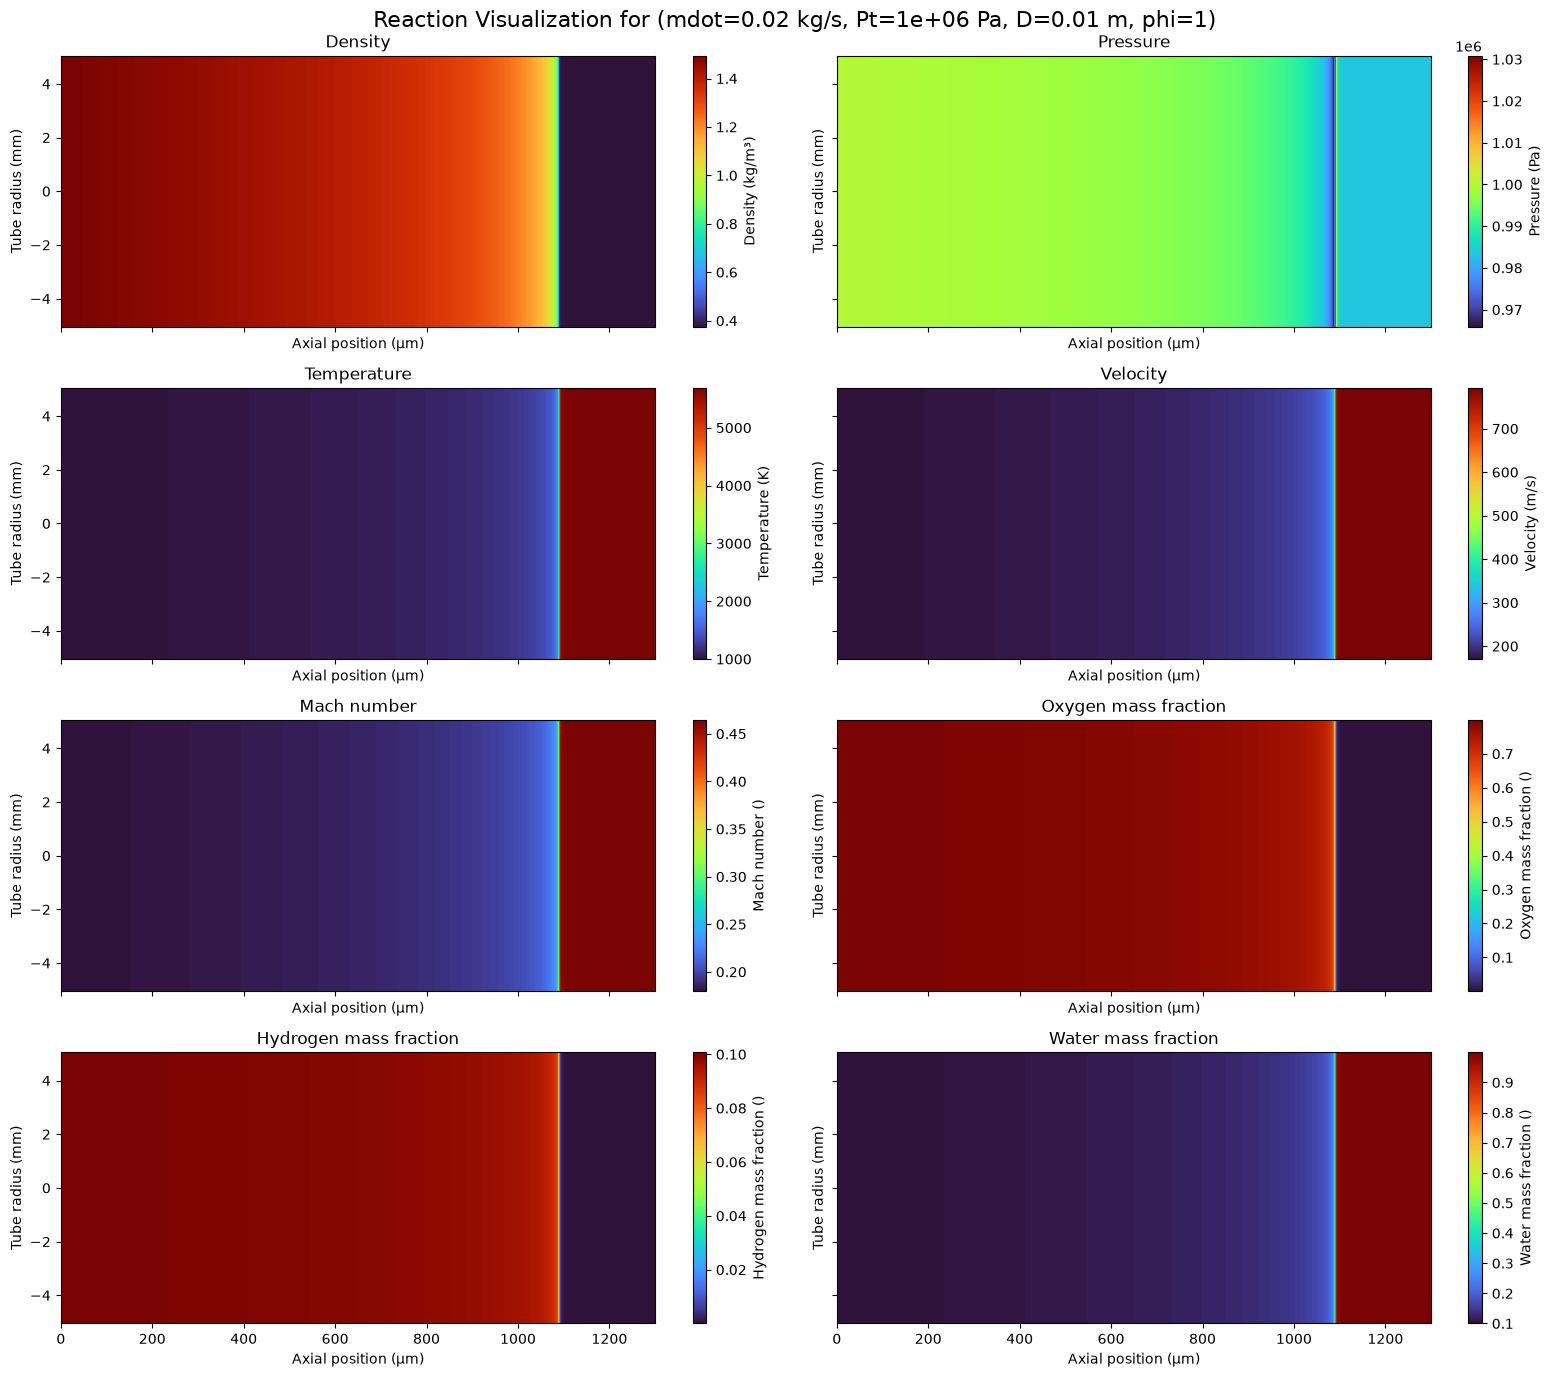

(mdot=500 kg/s, Pt=1.5e+07 Pa, D=0.8 m, phi=1)
  state0 = [2.2414e+01 1.0000e+03 4.4379e+01 7.9928e-01 1.0072e-01 1.0000e-01],  M0 = 0.047
  x_end = 82.625 um,  steps = 89
  outlet = [8.2457e+00 5.8014e+03 1.4926e+02 7.0532e-06 8.8876e-07 9.9999e-01]


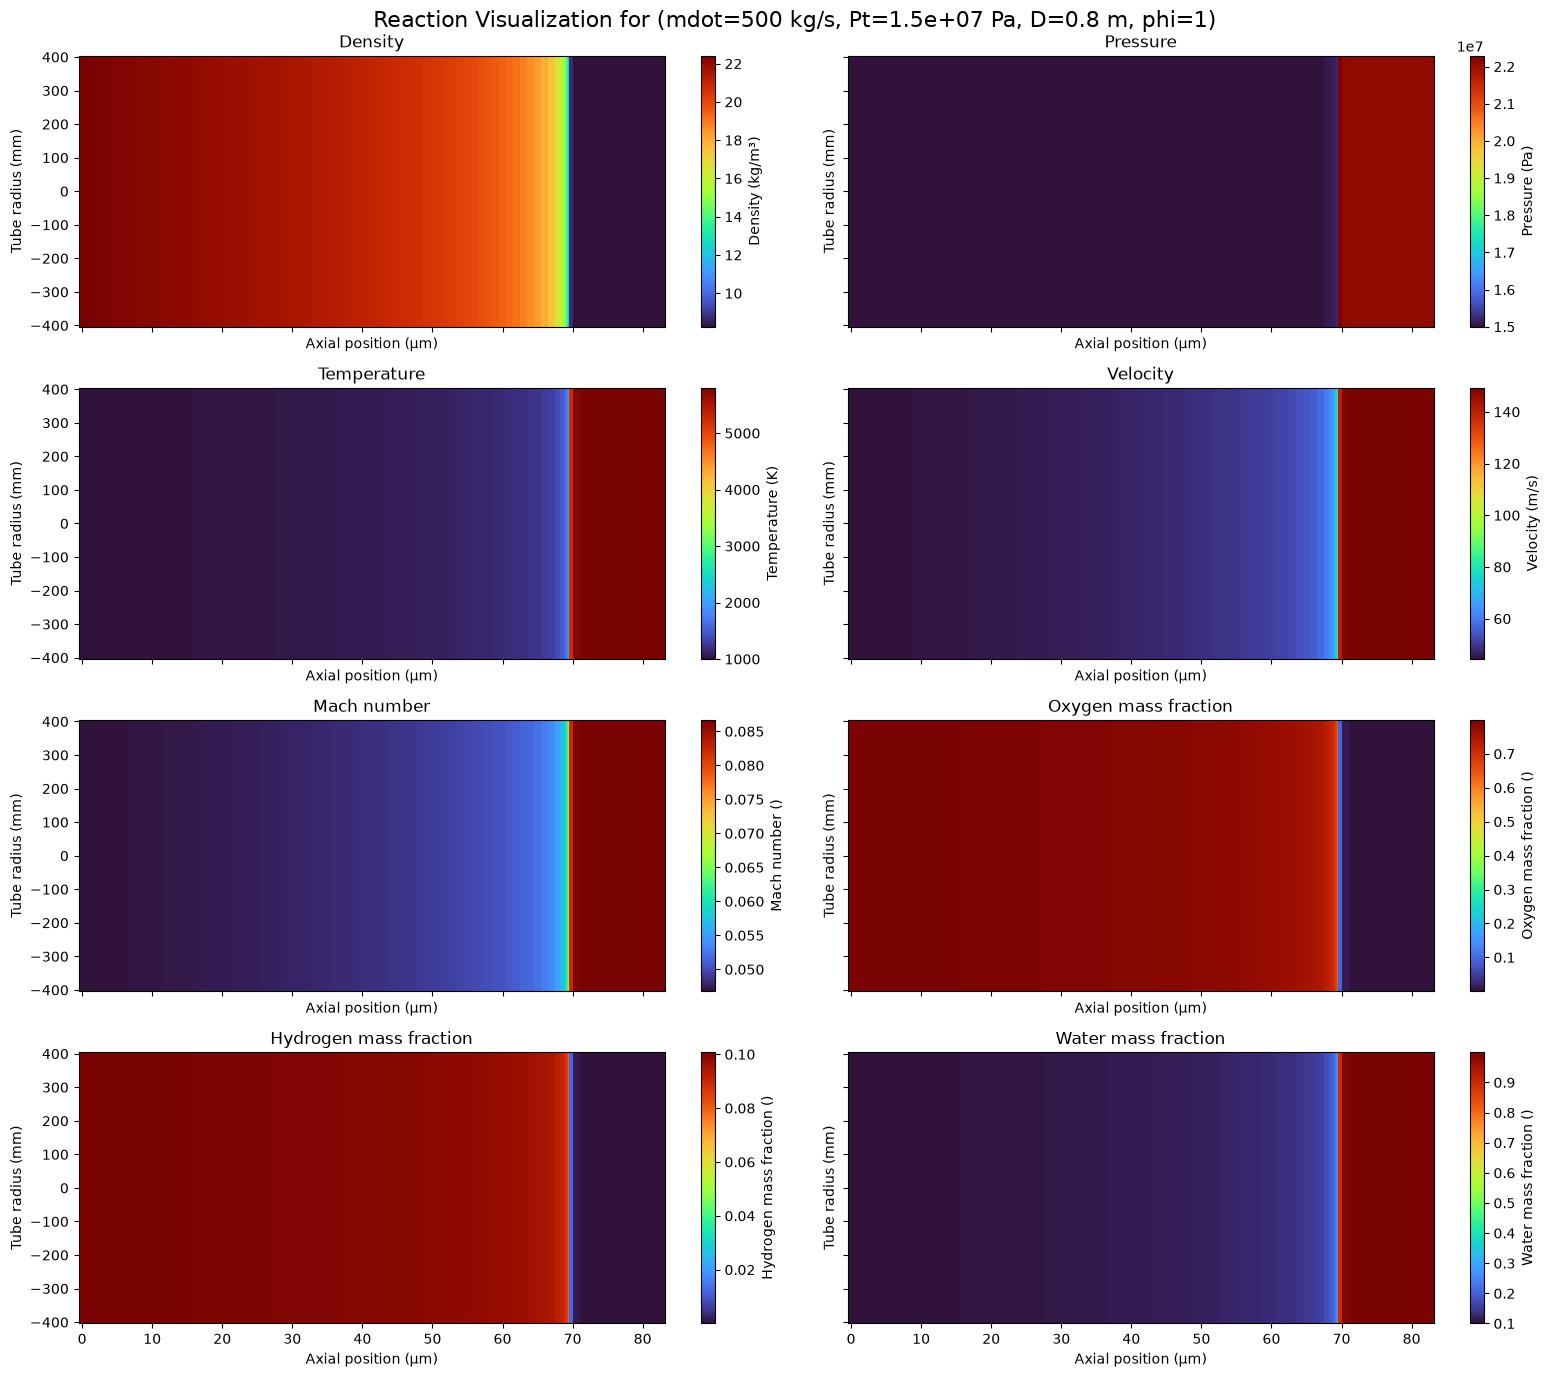

(mdot=1 kg/s, Pt=2.5e+06 Pa, D=0.1 m, phi=1)
  state0 = [3.7357e+00 1.0000e+03 3.4083e+01 7.9928e-01 1.0072e-01 1.0000e-01],  M0 = 0.036
  x_end = 152.000 um,  steps = 156
  outlet = [1.3828e+00 5.8024e+03 1.1409e+02 7.9049e-06 9.9608e-07 9.9999e-01]


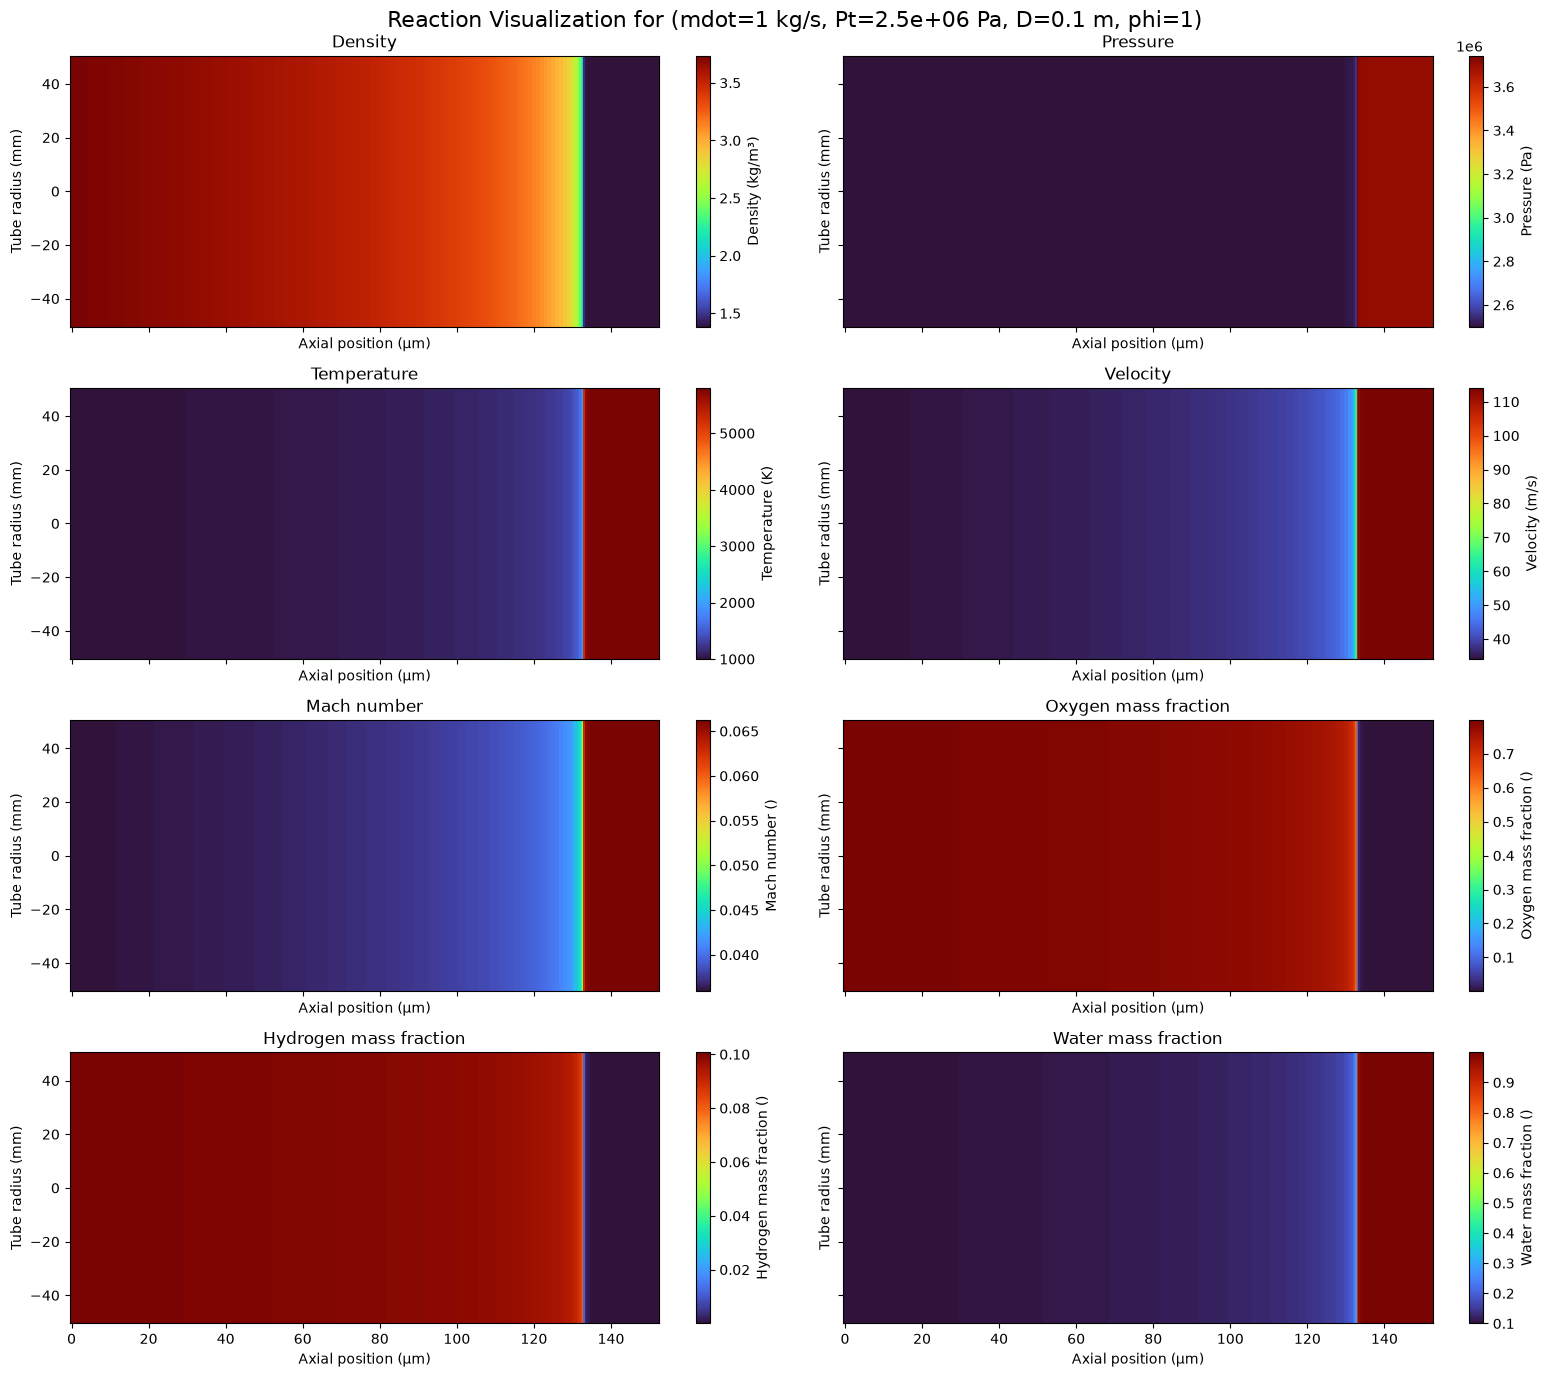

In [5]:
test_rcs     = [0.02,  1.0e6,  0.01, 1.0, Ar, Ea]
test_heavy   = [500.0, 15.0e6, 0.8,  1.0, Ar, Ea]
test_student = [1.0,   2.5e6,  0.10, 1.0, Ar, Ea]

cases = [test_rcs, test_heavy, test_student]
names = ["rcs thruster ignitor", "heavy lift engine ignitor", "student-built engine ignitor"]

for c, label in zip(cases, names):
    mdot, Pt, D, phi, Ar_, Ea_ = c
    full_name = f"(mdot={mdot:g} kg/s, Pt={Pt:.2g} Pa, D={D:g} m, phi={phi:g})"

    solver = chamber_solver(*c)
    s0, R, g, h1, h2, h3 = solver.initial_conditions()
    M0 = s0[2] / np.sqrt(g * R * s0[1])
    print(f"{full_name}")
    print(f"  state0 = {np.array2string(s0, precision=4)},  M0 = {M0:.3f}")

    x, states = solver.solve(dx=1e-6, Y_tol=1e-6)
    print(f"  x_end = {x[-1]*1e6:.3f} um,  steps = {len(x)-1}")
    print(f"  outlet = {np.array2string(states[-1], precision=4)}")

    solver.plot_tube(states, x, full_name)